## Becoming a DataVizard exercise 

This is an exercise about data visualization, welcome! You will use common python libraries, Matplotlib and Seaborn to create effective and clear visualizations. You will work with two datasets: a dataset containing information about the top ten grossing movies in each year, and a dataset with information about the population in Swiss communes. 

These are the visualizations we will make, and that you will use to solve the exercise:
- [Histogram](https://matplotlib.org/3.3.1/api/_as_gen/matplotlib.pyplot.hist.html)
- [Boxplot](https://matplotlib.org/api/_as_gen/matplotlib.pyplot.boxplot.html)
- [Scatterplot](https://matplotlib.org/api/_as_gen/matplotlib.pyplot.scatter.html)
- [Plot](https://matplotlib.org/api/_as_gen/matplotlib.pyplot.plot.html)
- [Jointplot](https://seaborn.pydata.org/generated/seaborn.jointplot.html)
- [Barplot](https://seaborn.pydata.org/generated/seaborn.barplot.html)
- [Violinplot](https://seaborn.pydata.org/generated/seaborn.violinplot.html)
- [Errorbar](https://matplotlib.org/3.1.1/api/_as_gen/matplotlib.pyplot.errorbar.html)
- [Filled plot](https://matplotlib.org/api/_as_gen/matplotlib.pyplot.fill_between.html)
- [Panels](https://matplotlib.org/api/_as_gen/matplotlib.pyplot.subplots.html)
- [Heatmap](https://seaborn.pydata.org/generated/seaborn.heatmap.html)
- [Log-log](https://matplotlib.org/3.1.1/api/_as_gen/matplotlib.pyplot.loglog.html)

In the linked documentation, you will find complete information, and a lot more details compared to what is outlined in this notebook. We will make simple visualizations, but you will notice that all of the visualizations consider many optional parameters. You are encouraged to explore them, and modify them to make the most efficient visualizations, and match your desired style.

Beyond Matplotlib and Seaborn, there are many more resources that might be useful for you, for example:
- [ggplot](http://ggplot.yhathq.com/)
- [plotly](https://plotly.com/python/)
- [Geopy](https://geopy.readthedocs.io/en/stable/) and [Folium](https://python-visualization.github.io/folium/)

Create your custom signature colorpalettes:
- [coolors](https://coolors.co/)

In [1427]:
# Let's load necessary libraries and the datasets
# "pip install seaborn" if necessary

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
import math

data_folder = './Data/'


movies = pd.read_csv(data_folder+'blockbusters.csv')
movies['worldwide_gross'] = movies['worldwide_gross'].str.replace('$', '', regex=False).str.replace(',', '', regex=False).astype(float)

commune_pop = pd.read_excel(data_folder+'communes_pop.xls',skiprows=5,skipfooter=7,
                            sheet_name='2017',names=['commune','population_Jan',
                                                     'birth_alive','death','natrual_increase',
                                                     'arrivals','departure','migratory_balance',
                                                     'divergence_statistic','population_Dec','variation_num',
                                                     'variation_ratio'])

pop_per_commune = commune_pop[[name.startswith('......') for name in commune_pop.commune]].copy()

### Note:
#### In case you have trouble opening the "communes_pop.xls" file, try installing an input library: "pip install openpyxl"

# 1. Tutorial: Using data visualization libraries

We will use the blockbusters dataset. Summary of the features:
- *Main_Genre*: the primary genre of the movie
- *Genre_2*
- *Genre_3*
- *imdb_rating*
- *length*: movie length in minutes
- *rank_in_year*: rank among the top 10 movies released that year
- *rating*: audience rating
- *studio*: the studio that produced the movie
- *title*: movie title
- *worldwide_gross*: total worldwide revenue in dollars
- *year*: year of release


## Visualizing a single variable

- First we will see how to visualize a single variable using matplotlib library. Let's focus on "Worldwide gross revenue" column of the dataframe and inspect the distribution, using histogram and boxplot.
- Notice the use of  plt.xlabel(), plt.ylabel(), plt.title() - every visualization should have axis labeled, and a title!
- plt.hist() takes a couple of important arguments: bins - the number of bins, and range - the range of values considered in the histogram.

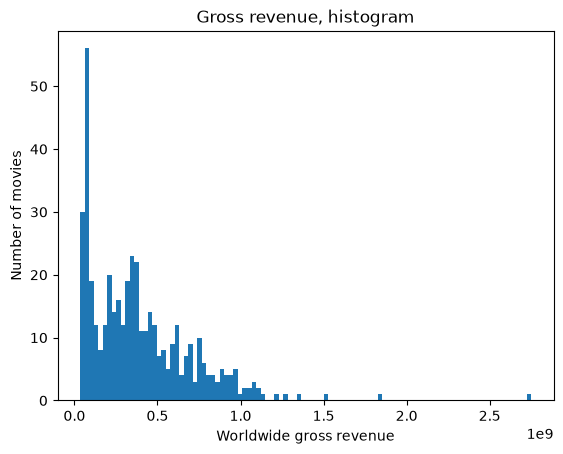

In [1428]:
#we use pandas wrapper
#movies['worldwide_gross'].hist(bins = 100)

#alternatively, we can use matplotlib directly
plt.hist(movies['worldwide_gross'].values, bins = 100)

plt.xlabel('Worldwide gross revenue')
plt.ylabel('Number of movies')
plt.title('Gross revenue, histogram');

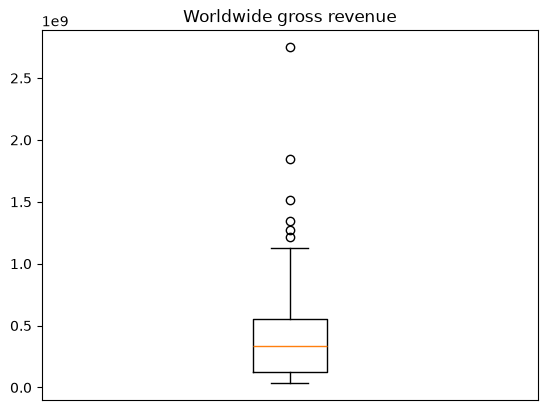

In [1429]:
plt.boxplot(movies['worldwide_gross'])
plt.xticks([])
plt.title('Worldwide gross revenue');

## Visualizing two continuous variables

- Let's see if blockbusters with higher ratings also make more revenue!
- There are many ways how a relationship between two variables can be examined. The simplest one is a scatterplot, using plt.scatterplot().

Text(0, 0.5, 'IMDB rating')

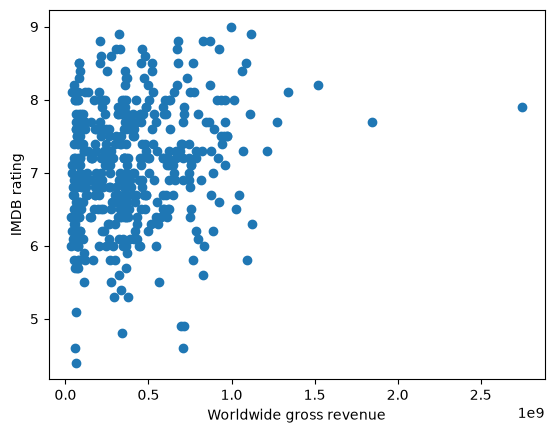

In [1430]:
plt.scatter(movies['worldwide_gross'], movies['imdb_rating'])

plt.xlabel('Worldwide gross revenue')
plt.ylabel('IMDB rating')

- Visually examining the plot, how do you interpret the relationship between revenue and IMDB rating?
- Markers indicatig the datapoints seem too large, and we cannot get a sense of the distribution in the area of the plot where the markers are overlapping.
- We'll try to make the markers smaller by specifying a small "s" size parameter.

Text(0, 0.5, 'IMDB rating')

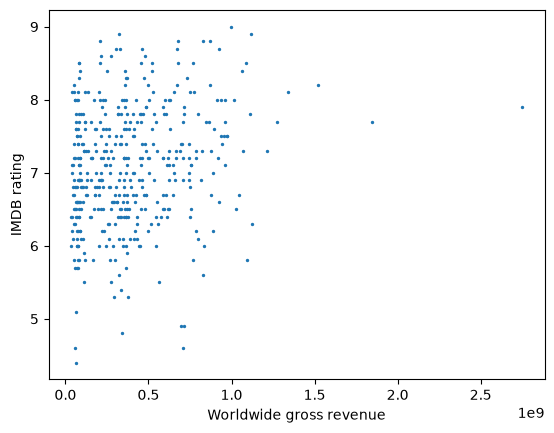

In [1431]:
plt.scatter(movies['worldwide_gross'], movies['imdb_rating'], s = 2)

plt.xlabel('Worldwide gross revenue')
plt.ylabel('IMDB rating')

- Do you notice anything strange? What could be the reason?

Scatterplots are not useful when the number of datapoints is very large, as it becomes hard to interpret it. Seaborn library offers many alternative effective ways of visualizing join distributions. 

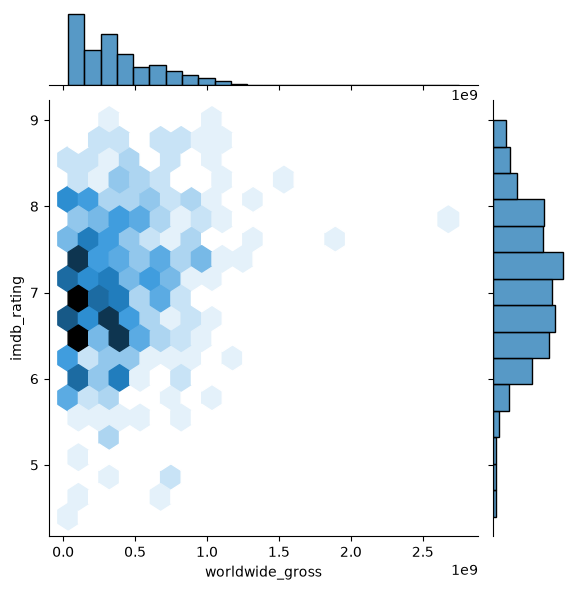

In [1432]:
sns.jointplot(x=movies['worldwide_gross'], y=movies['imdb_rating'], kind="hex")

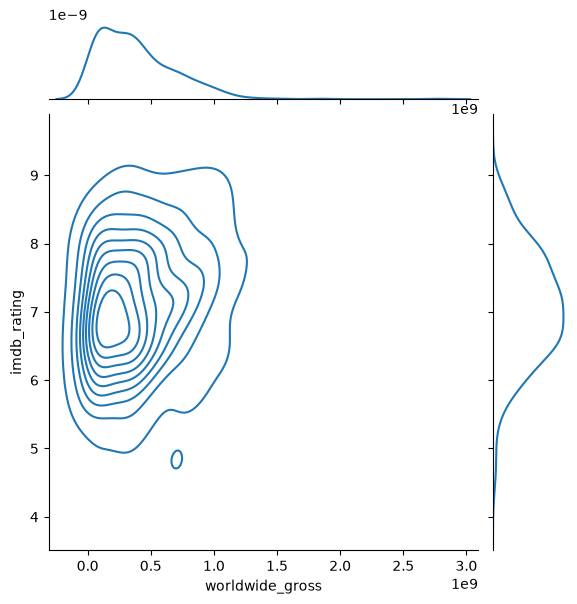

In [1433]:
sns.jointplot(data = movies, x = 'worldwide_gross', y = 'imdb_rating', kind="kde")


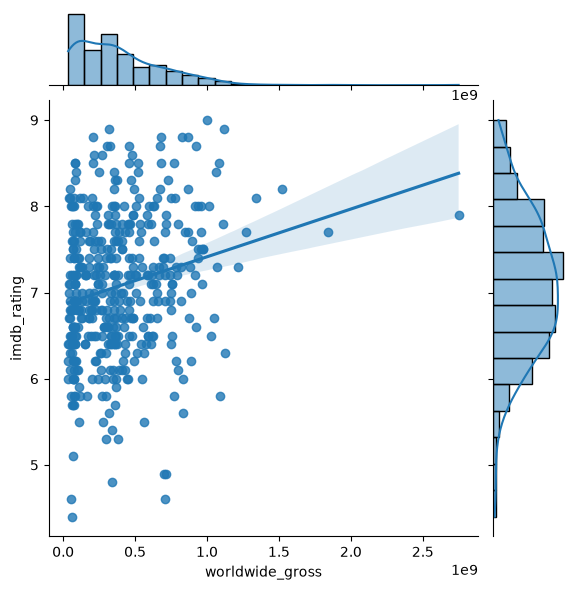

In [1434]:
sns.jointplot(data = movies, x = 'worldwide_gross', y = 'imdb_rating', kind="reg")

## Visualizing two variables, continuous and categorical

- Let's consider the five most prevalent genres, and examine the revenue.
- We'll show barplot (we get errorbars by default, how neat!), boxplot, and violinplot. Seaborn offers many more compelling visualizations. We will stop here, but see the gallery for more examples: https://seaborn.pydata.org/examples/index.html

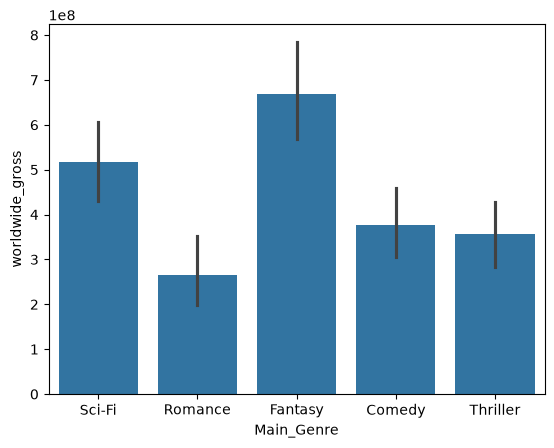

In [1435]:
ax = sns.barplot(x="Main_Genre", y="worldwide_gross", data=movies.loc[movies['Main_Genre'].isin(['Thriller','Comedy',
                                                                                      'Fantasy','Sci-Fi','Romance'])])

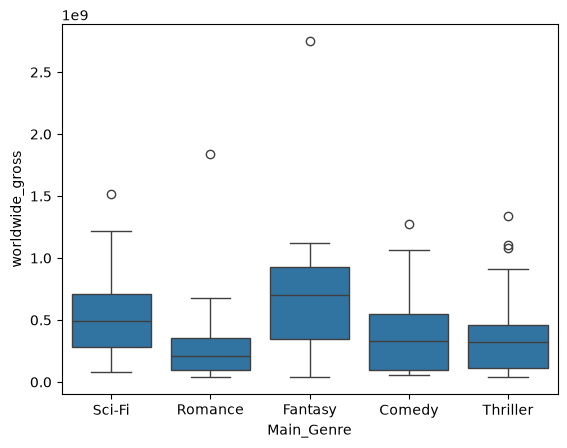

In [1436]:
ax = sns.boxplot(x="Main_Genre", y="worldwide_gross", data=movies.loc[movies['Main_Genre'].isin(['Thriller','Comedy',
                                                                                      'Fantasy','Sci-Fi','Romance'])])

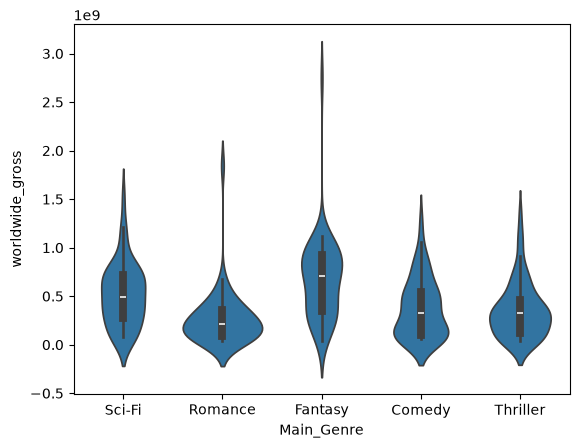

In [1437]:
ax = sns.violinplot(x="Main_Genre", y="worldwide_gross", data=movies.loc[movies['Main_Genre'].isin(['Thriller','Comedy',
                                                                                      'Fantasy','Sci-Fi','Romance'])])

# 2. Exercises: Making more advanced visualizations


To make a good data visualization, we first need a clear idea of what we want to visualize! Do we aggregate the data, and how? What quantity should be on the different axis? How to use colors and item sizes? It often helps to sketch the visualization by hand before coding it up. By doing that, we can also give ourselves a moment to speculate what the visualization could look like under different hypotheses.

In the next three excercises, you are provided with descriptions and rough sketches of visualizations that are possibly useful to understand the movies dataset.


## 2.1 Visualizing uncertainty

- How did the average revenue of blockbusters evolve? Visualize the average yearly worldwide gross revenue, together with the standard deviation. Below, you are provided with two rough sketches of how the visualization could look like. We could indicate the margin of error with lines with caps, or by contouring between the upper and lower bound.

- Hints: use Matplotlib errorbar and fill_between functions.

- Did the average revenue increase/decrease over time? What do you observe?


<img src="figure0.jpg" style="width: 400px;" align="left" />
<img src="figure1.jpg" style="width: 400px;" align="left"/>


<br>


In [1438]:
from IPython.display import display
display(movies.head(5))

,Main_Genre,Genre_2,Genre_3,imdb_rating,length,rank_in_year,rating,studio,title,worldwide_gross,year
0,Action,Adventure,Drama,7.4,135,1,PG-13,Walt Disney Pictures,Black Panther,700059566.0,2018
1,Action,Adventure,Sci-Fi,8.5,156,2,PG-13,Walt Disney Pictures,Avengers: Infinity War,678815482.0,2018
2,Animation,Action,Adventure,7.8,118,3,PG,Pixar,Incredibles 2,608581744.0,2018
3,Action,Adventure,Drama,6.2,129,4,PG-13,Universal Pictures,Jurassic World: Fallen Kingdom,416769345.0,2018
4,Action,Comedy,NaN,7.8,119,5,R,20th Century Fox,Deadpool 2,318491426.0,2018


year imdb_rating                length            rank_in_year            \
               mean       std        mean        std         mean       std   
0  1975    6.642857  0.727684  110.571429  16.029734          7.0  2.160247   
1  1976    6.800000  1.041367  110.900000  33.301485          5.5  3.027650   
2  1977    7.260000  0.773448  119.700000  24.088033          5.5  3.027650   
3  1978    7.000000  0.816497  120.000000  25.686140          5.5  3.027650   
4  1979    7.160000  0.946573  118.000000  17.568912          5.5  3.027650   

  worldwide_gross                
             mean           std  
0    4.096674e+07  6.449858e+06  
1    6.642076e+07  2.287164e+07  
2    9.808576e+07  8.039820e+07  
3    8.944416e+07  3.714570e+07  
4    8.086015e+07  1.129196e+07

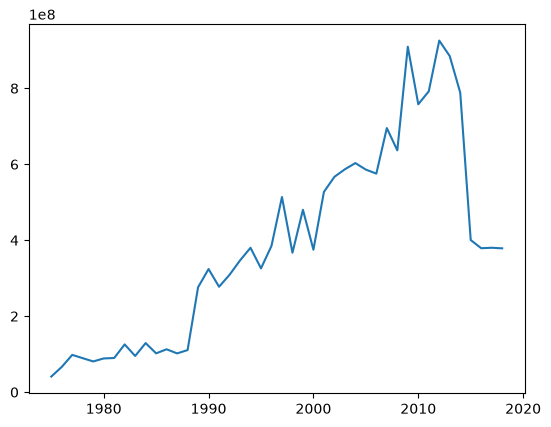

In [1439]:
# Calculate yearly stats across movies here
yearly_stats = (
    movies
    .drop(columns=["Main_Genre", "Genre_2", "Genre_3", "rating", "studio", "title"])
    .groupby("year")
    .agg(["mean", "std"])
    .reset_index()
)

display(yearly_stats.head(5))
plt.plot(yearly_stats["year"], yearly_stats["worldwide_gross"]["mean"])

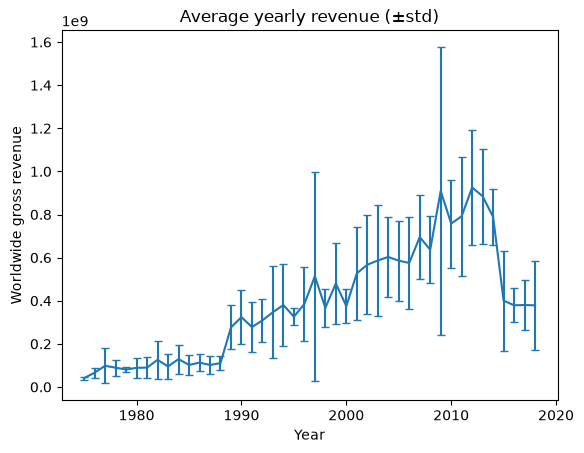

In [1440]:
# Write your code to make plot with errorbars here
plt.errorbar(
    yearly_stats["year"], 
    yearly_stats["worldwide_gross"]["mean"], 
    yerr=yearly_stats["worldwide_gross"]["std"], 
    capsize=3)

plt.xlabel("Year")
plt.ylabel("Worldwide gross revenue")
plt.title("Average yearly revenue (±std)")
plt.show()

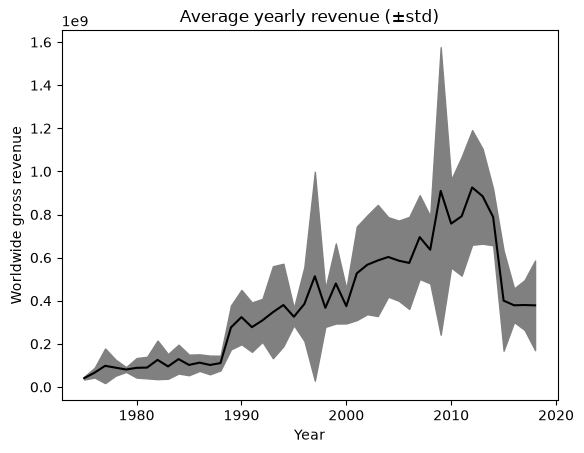

In [1441]:
# Write your code to make filled plot here
plt.fill_between(
    yearly_stats["year"], 
    yearly_stats["worldwide_gross"]["mean"] + yearly_stats["worldwide_gross"]["std"],
    yearly_stats["worldwide_gross"]["mean"] - yearly_stats["worldwide_gross"]["std"],
    color="gray",
    )
plt.plot(yearly_stats["year"], yearly_stats["worldwide_gross"]["mean"], color = 'black')
"""
fill between fills an area between to curves, so it takes x, y1 abd y2
to add the middle mean curve we can just add a plt.plot call (everything drawn before plt.show() ends up on the same axes)
"""

plt.xlabel("Year")
plt.ylabel("Worldwide gross revenue")
plt.title("Average yearly revenue (±std)")
plt.show()

## 2.2 Creating panels

- Next, we want to understand how long the blockbusters are in the different genres. When working with a large number of categories (we have 16 genres in the movies dataset), the visualizations easily become cluttered, and it becomes useful to make panels with small subplots.

- Make a 4x4 panel for the 16 genres. In each subplot, show a histogram with the distribution of movie lengths for different categories. Below, find a skets of how this visualization could look like. Note the same x- and y-scale that allows comparison between categories!

- Hints: use Matplotlib subplots function to initialize the subplotting axes.

- What genres do the longest movies belong too? What can you say about the length of Comedy and animation movies?

- How could we assign different color to each subplot (each genre)? What type of palette would be the best choice? Make a variation of the visualzation where each genre is visualized in a different color.

<img src="figure3.jpg" style="width: 500px;" align="left">

In [1442]:
# Calculate stats by genre here
genre_stats = movies.groupby("Main_Genre")["length"].agg(list).reset_index()
"""
.groupby("Main_Genre")["length"] splits the movies by genre, keep only the length column
.agg(list) makes a list with all the values from each .groupby groups
.reset_index() moves the grouped by column back into a normal column and gives the rows a fresh 0, 1, 2, … index. 
(After a groupby, the column you grouped by becomes the index of the result, the row labels on the left, instead of a regular column.)
"""
display(genre_stats.head(5))

,Main_Genre,length
0,Action,"[135, 156, 129, 119, 147, 118, 135, 112, 152, ..."
1,Adventure,"[146, 122, 106, 139, 140, 127, 163, 121, 127, ..."
2,Animation,"[118, 90, 100, 90, 108, 108, 94, 91, 98, 91, 1..."
3,Comedy,"[102, 104, 88, 93, 102, 103, 106, 103, 93, 96,..."
4,Crime,"[128, 120, 147, 133, 128, 130, 111, 104, 85, 1..."


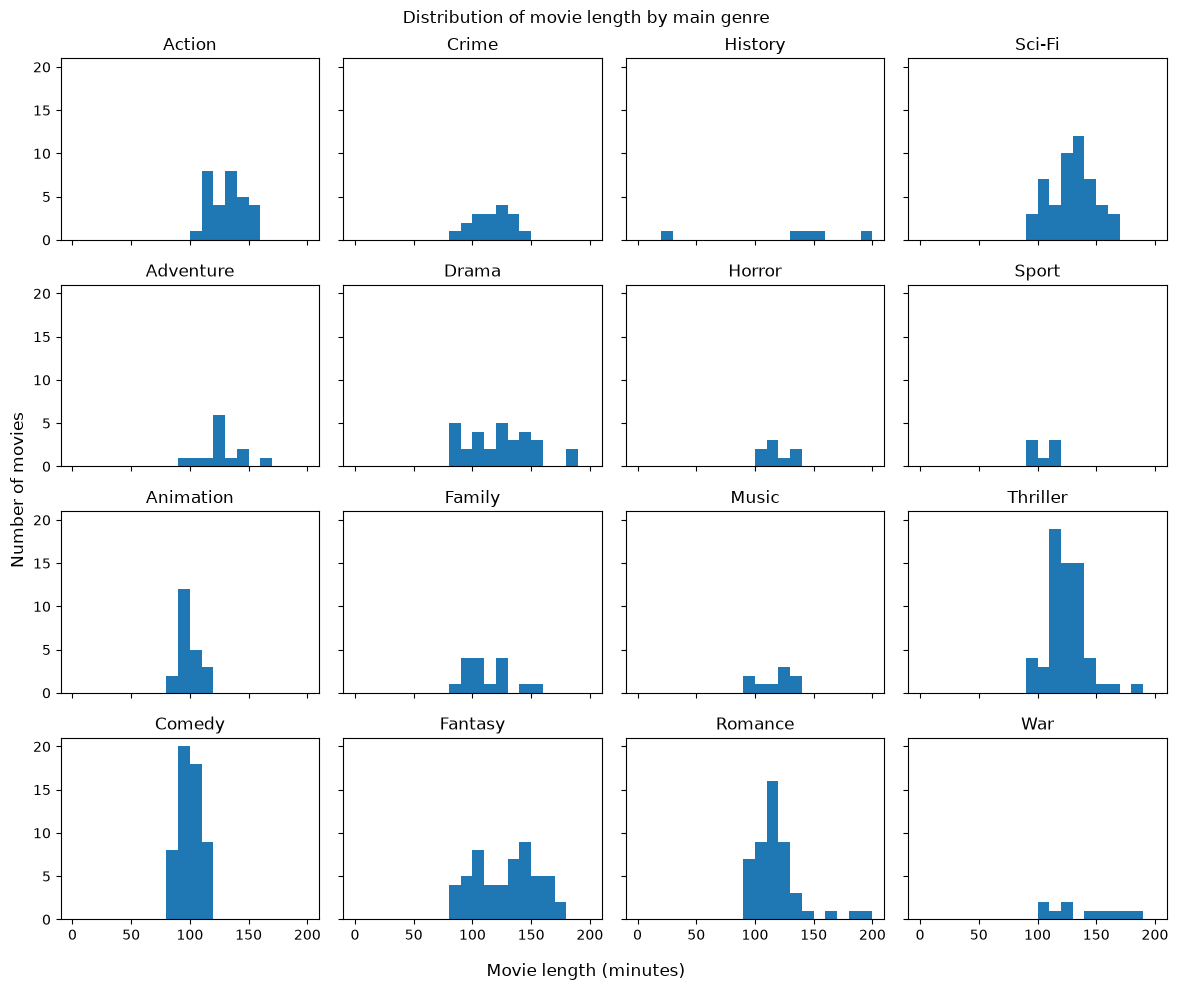

In [1443]:
# Write your code to make 4x4 panel here

fig, ax = plt.subplots(4,4,figsize= (12,10), sharey = True, sharex = True)

for i in range(len(genre_stats)):
    sbplt = ax[i%4, i//4] # % is modulo (0,1,2,3,0,1,2,3,0,...) and // is int division (0,0,0,0,1,1,1,1,2,2,2,2,3,3,3,3)
    sbplt.hist(genre_stats.length[i],range = [0,200],bins = 20)
    sbplt.set_title(genre_stats["Main_Genre"][i])

fig.supxlabel("Movie length (minutes)") # sup... = one label for the whole figure, not each subplot
fig.supylabel("Number of movies")
fig.suptitle("Distribution of movie length by main genre")
plt.tight_layout() # fix spacing so titles and ticks don't overlap
plt.show()


In [1444]:
# Write your interpretation here
"""
Looking at the histograms, the longest movies belong to the history and romance genres. 
The Comedy and animation genres have the shortest movies overall.

The genres are categories with no natural order, so a qualitative (categorical) palette fits: 
clearly distinct colors that don’t suggest “more” or “less”. 
Seaborn can generate one:
colors = sns.color_palette("tab20", len(genre_stats))
Then pass color=colors[i] to hist inside the loop. tab20 has 20 distinct colors, enough for 16 genres. 
Smaller palettes like tab10 would repeat colors.
"""

'\nLooking at the histograms, the longest movies belong to the history and romance genres. \nThe Comedy and animation genres have the shortest movies overall.\n\nThe genres are categories with no natural order, so a qualitative (categorical) palette fits: \nclearly distinct colors that don’t suggest “more” or “less”. \nSeaborn can generate one:\ncolors = sns.color_palette("tab20", len(genre_stats))\nThen pass color=colors[i] to hist inside the loop. tab20 has 20 distinct colors, enough for 16 genres. \nSmaller palettes like tab10 would repeat colors.\n'

## 2.3 Heatmaps

- What studios make blockbusters in which genre? 

- There are many studios and many genres. When working with two variables that both have many different categories, there is often no space for representing each combination of two categories with a detailed plot (such as barplot of boxplot). It becomes useful to represent each stratum with one number, indicated with color in a heatmap. Such visualizations are useful to quickly understand the data.

- Visualize the number of blockbusters made by each studio, of each genre. You will find below a rough sketch. Hint: use Seaborn heatmap function. 

- Finally, with a heatmap we can represent three variables, by coding a third variable with color. Try to understand what is the relationship between genres by understanding the co-occurence patterns between the main and secondary genre. What is the average worldwide gross revenue for movies with different combinations of main and second genre?

- You should be able to easily answer the following questions from the two visualizations: What genres do the majority of movies made by Warner Bros studio fall into? What is the most successful genre of Walt Disney pictures movies? What studio made the largest number of Romance blockbusters? Which combination of genres brings the highest revenue?



<img src="figure4.jpg" style="width: 500px;" align="left">

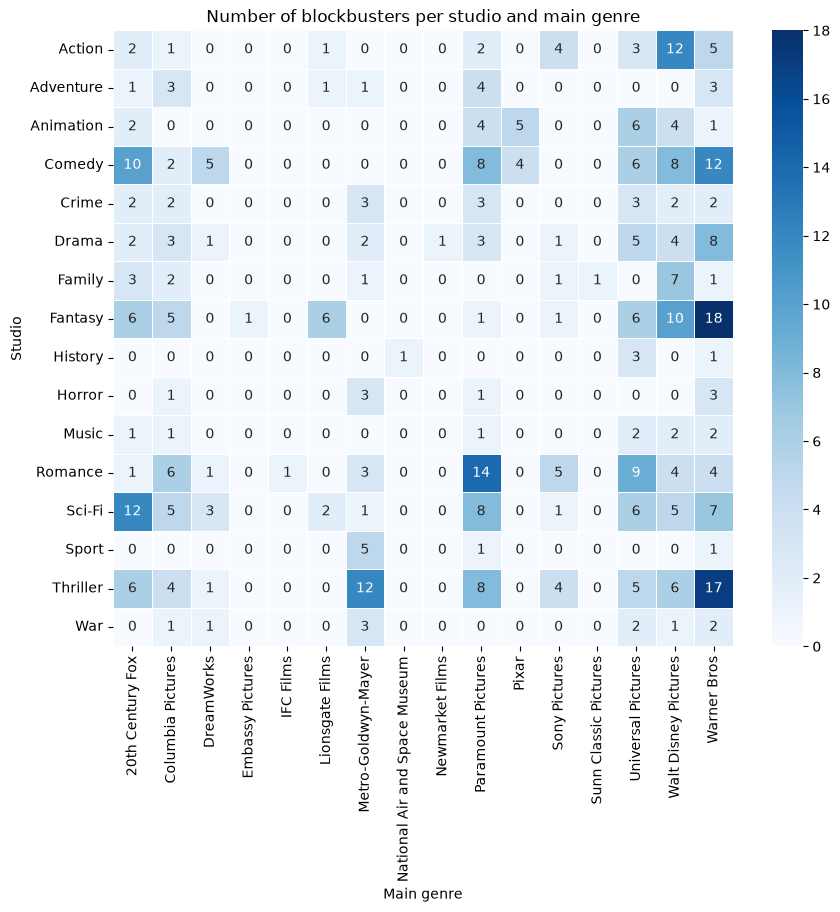

'\nannot=True writes the number in each cell.\nfmt="d" formats the annotations as integers.\ncmap="Blues": counts go from low to high, so a sequential colormap (light to dark) fits.\nlinewidths=0.5 draws thin lines between cells, which makes a large grid easier to read.\n'

In [1445]:
# Write your code to make the first heatmap here
"""
heatmap() colors a grid of numbers, where every cell is one value
What the heatmap needs is a matrix like this:
Main_Genre     Action  Comedy  Drama  ...
studio
Fox                12       5      3
Sony                8       9      2
Warner Bros        15       4      6
...

pd.crosstab exists for exactly this job: counting how often each combination of two categorical columns occurs.
"""
studio_genre = pd.crosstab(movies["Main_Genre"], movies["studio"])

plt.figure(figsize=(10, 8))
sns.heatmap(studio_genre, annot=True, fmt="d", cmap="Blues", linewidths=0.5)
plt.title("Number of blockbusters per studio and main genre")
plt.xlabel("Main genre")
plt.ylabel("Studio")
plt.show()
"""
annot=True writes the number in each cell.
fmt="d" formats the annotations as integers.
cmap="Blues": counts go from low to high, so a sequential colormap (light to dark) fits.
linewidths=0.5 draws thin lines between cells, which makes a large grid easier to read.
"""

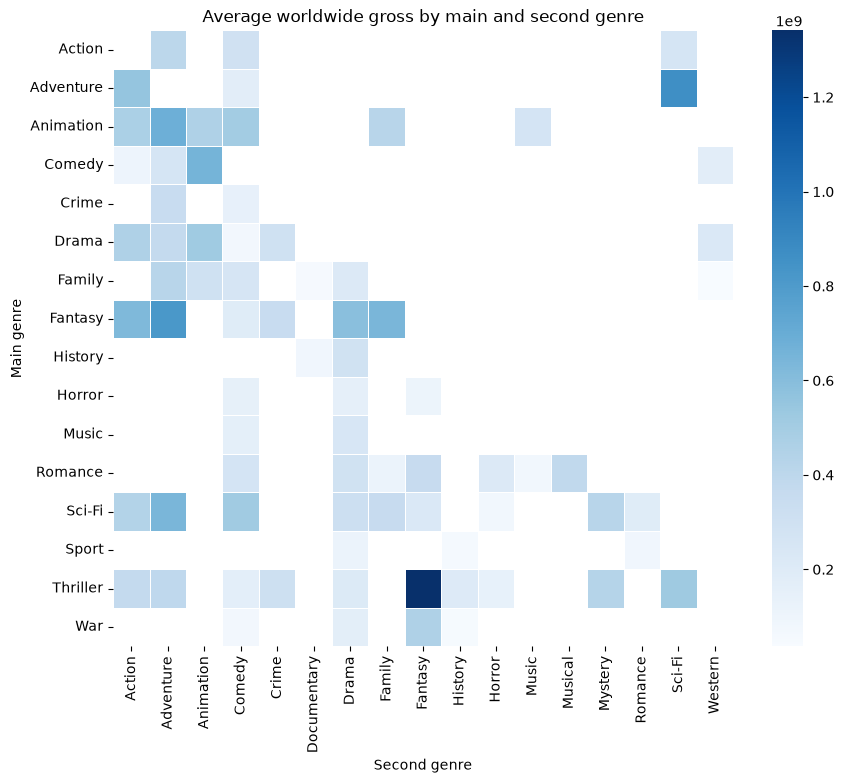

In [1446]:
# Write your code to make the second heatmap here
"""
What the heatmap should show:
Rows: main genre (Main_Genre)
Columns: second genre (Genre_2)
Color of the cell: the average worldwide gross of all movies with that combination
    (NaN = combination never occurs -> shown as a blank cell)

So the heatmap needs a matrix like this:
Genre_2       Action    Adventure  Comedy   ...
Main_Genre
Action        NaN       4.1e+08    2.3e+08
Adventure     3.8e+08   NaN        NaN
Comedy        1.9e+08   2.7e+08    NaN
...

.crosstab() also works here as it can have a third parameter (values: array of values to aggregate according to the factors)
"""

genre_relationship = pd.crosstab(movies["Main_Genre"], movies["Genre_2"], movies["worldwide_gross"], aggfunc="mean")
"""
aggfunc is required when values is given
"""

plt.figure(figsize=(10, 8))
sns.heatmap(genre_relationship, annot=False, cmap="Blues", linewidths=0.5)
plt.title("Average worldwide gross by main and second genre")
plt.xlabel("Second genre")
plt.ylabel("Main genre")
plt.show()

- **Warner Bros:** the majority of its blockbusters are Fantasy (18), Thriller (17) and Comedy (12), which together make up just over half of its 87 movies.
- **Walt Disney Pictures:** its most successful genre is Action, with the most blockbusters (12), followed by Fantasy (10). (This is based on the number of blockbusters, since the first heatmap shows counts, not revenue.)
- **Romance:** Paramount Pictures made the largest number of Romance blockbusters (14), ahead of Universal (9).
- **Highest-revenue combination:** Thriller as main genre with Fantasy as second genre, averaging about $1.3 billion, far above all other combinations. Adventure + Sci-Fi and Fantasy + Adventure follow at roughly $0.8 billion. Some combinations contain very few movies, so their averages should be interpreted with caution.

## 2.4 Be a show-off

Finally, we did not explore the impact of the rank of the movie among the top ten. How is the rank among the top ten related to the genres? What kind of visualization can be suitable to understand this better? To practice your data viz skills, sketch a potential visualization on a piece of paper, and then implement it using the appropriate type of visualization.

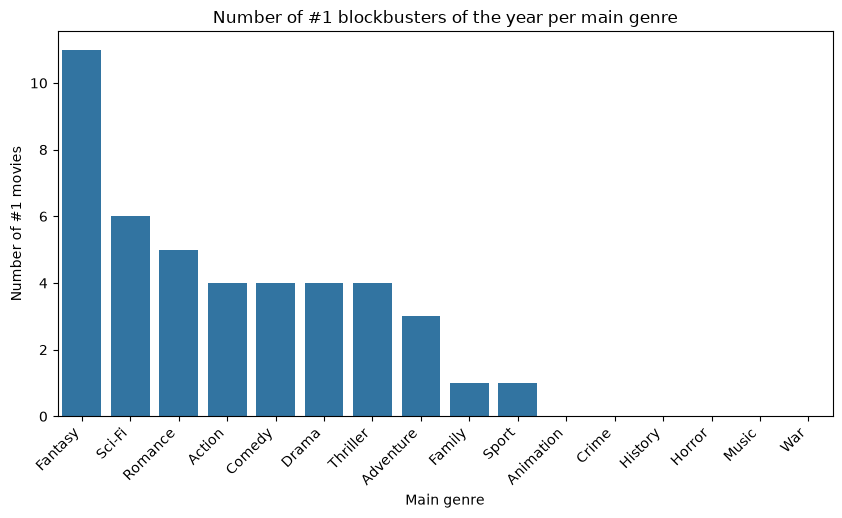

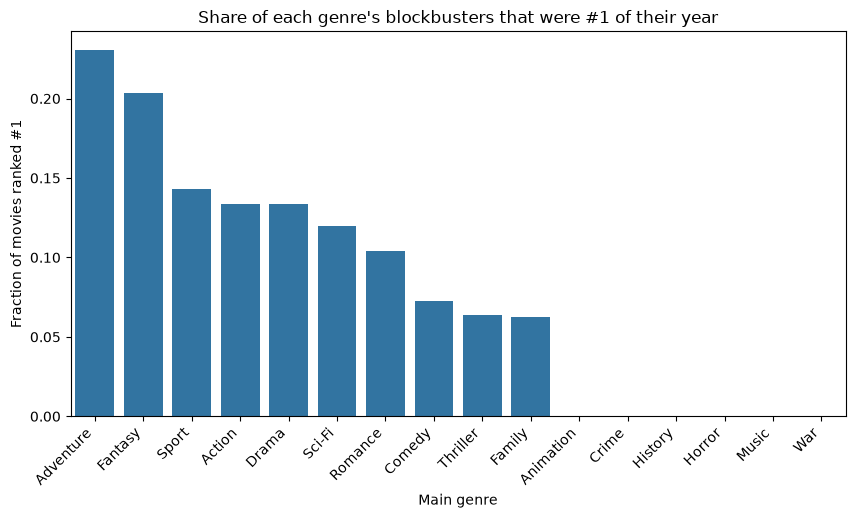

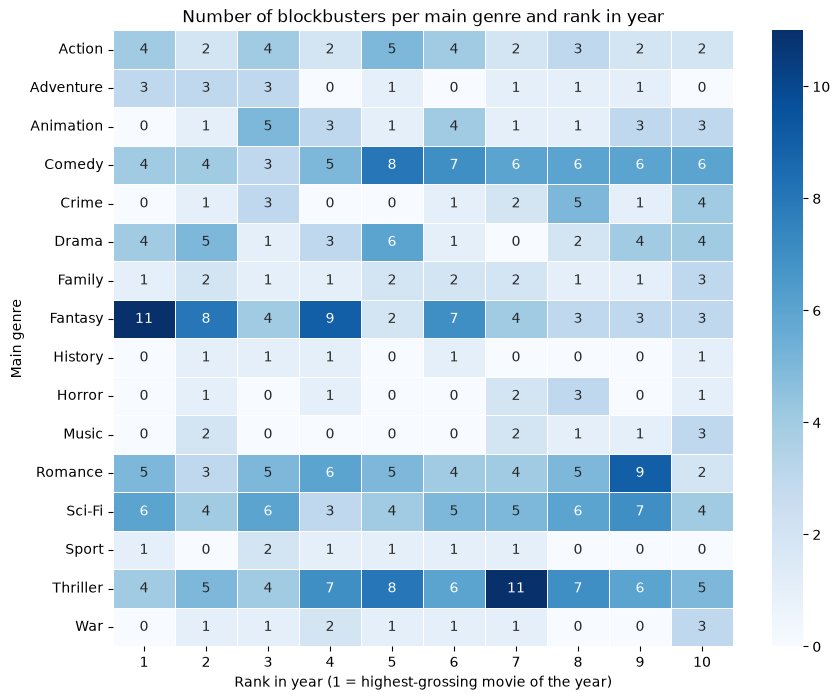

In [1447]:
# Write your dataviz show-off code here
"""
I want to count the number of movies with a #1 ranking for each genre.
Sadly pandas has no dedicated “count if” function. 
The usual way is to first build the True/False column, then sum it per group. 
Since True counts as 1, a sum is a count:
"""
genre_n1ranking = (movies["rank_in_year"] == 1).groupby(movies["Main_Genre"]).sum().sort_values(ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(x=genre_n1ranking.index, y=genre_n1ranking.values)
plt.title("Number of #1 blockbusters of the year per main genre")
plt.xlabel("Main genre")
plt.ylabel("Number of #1 movies")
plt.xticks(rotation=45, ha="right")
plt.show()

"""
The bar plot counts #1 movies, but genres with many blockbusters will naturally have more #1s. 
To see which genres are best at reaching the top, divide the number of #1 movies by the total number of movies.
To do so we can just use mean on True/False column: (number of True) / (number of rows) = fraction of #1 movies per genre.
"""
share_n1 = (movies["rank_in_year"] == 1).groupby(movies["Main_Genre"]).mean().sort_values(ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(x=share_n1.index, y=share_n1.values)
plt.title("Share of each genre's blockbusters that were #1 of their year")
plt.xlabel("Main genre")
plt.ylabel("Fraction of movies ranked #1")
plt.xticks(rotation=45, ha="right")
plt.show()

"""
To go further, I do a heatmap of genre and ranking and the cells showing the number of movies
"""
genre_ranking = pd.crosstab(movies["Main_Genre"], movies["rank_in_year"])

plt.figure(figsize=(10, 8))
sns.heatmap(genre_ranking, annot=True, fmt="d", cmap="Blues", linewidths=0.5)
plt.title("Number of blockbusters per main genre and rank in year")
plt.xlabel("Rank in year (1 = highest-grossing movie of the year)")
plt.ylabel("Main genre")
plt.show()


## Part 3: Visualizing skewed distributions

__3.A__ Familiarize yourself with the "pop_per_commune" dataframe, that contains information about each commune, and its population. Plot a histogram of the population counts (population_Dec) and explain your observations. Do not use a log-scale plot for now. What does this histogram tell you about urban and rural communes in Switzerland? Are there any clear outliers on either side, and if so, which communes?

In [1448]:
# Write your code here
display(pop_per_commune)

,commune,population_Jan,birth_alive,death,natrual_increase,arrivals,departure,migratory_balance,divergence_statistic,population_Dec,variation_num,variation_ratio
3,......0001 Aeugst am Albis,1977,10,7,3,129,165,-36,-3,1941,-36,-1.820941
4,......0002 Affoltern am Albis,11900,128,93,35,1239,1029,210,1,12146,246,2.067227
5,......0003 Bonstetten,5435,47,25,22,374,322,52,3,5512,77,1.416743
6,......0004 Hausen am Albis,3571,27,20,7,298,217,81,5,3664,93,2.604313
7,......0005 Hedingen,3687,31,20,11,224,231,-7,3,3694,7,0.189856
...,...,...,...,...,...,...,...,...,...,...,...,...
2402,......6806 Vendlincourt,557,7,5,2,33,34,-1,-1,557,0,0.000000
2403,......6807 Basse-Allaine,1225,6,14,-8,64,59,5,-10,1212,-13,-1.061224
2404,......6808 Clos du Doubs,1321,11,16,-5,69,72,-3,-10,1303,-18,-1.362604
2405,......6809 Haute-Ajoie,941,8,7,1,68,63,5,1,948,7,0.743889


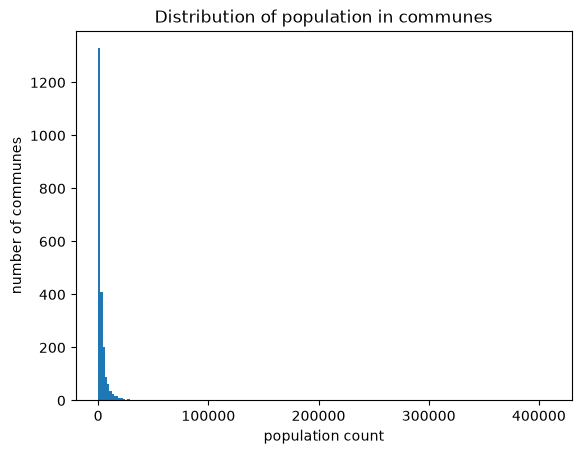

In [1449]:
#histogram
plt.hist(pop_per_commune["population_Dec"], bins=200) #use bins="auto" first
plt.title("Distribution of population in communes")
plt.xlabel("population count")
plt.ylabel("number of communes")
plt.show()

The population count distribution is very concentrated at smaller populations. It's strongly right skewed, so the outliers are on the right side.

In [1450]:
#find outliers
sorted_pop_per_commune = pop_per_commune.sort_values("population_Dec")
display(sorted_pop_per_commune.head(5))
display(sorted_pop_per_commune.tail(10))

,commune,population_Jan,birth_alive,death,natrual_increase,arrivals,departure,migratory_balance,divergence_statistic,population_Dec,variation_num,variation_ratio
1701,......5102 Corippo,14,0,0,0,0,2,-2,0,12,-2,-14.285714
954,......2549 Kammersrohr,30,1,0,1,0,2,-2,0,29,-1,-3.333333
2191,......6172 Bister,30,0,0,0,2,0,2,0,32,2,6.666667
214,......0708 Schelten,37,0,1,-1,4,6,-2,0,34,-3,-8.108108
1357,......3707 Lohn (GR),44,0,0,0,0,2,-2,0,42,-2,-4.545455


,commune,population_Jan,birth_alive,death,natrual_increase,arrivals,departure,migratory_balance,divergence_statistic,population_Dec,variation_num,variation_ratio
225,......0371 Biel/Bienne,54456,626,593,33,3569,3432,137,14,54640,184,0.337887
1741,......5192 Lugano,63932,517,620,-103,3963,4203,-240,-95,63494,-438,-0.685103
1156,......3203 St. Gallen,75481,865,714,151,5574,5636,-62,-48,75522,41,0.054318
546,......1061 Luzern,81592,916,819,97,6691,7199,-508,220,81401,-191,-0.234092
165,......0230 Winterthur,109775,1386,835,551,6650,6171,479,107,110912,1137,1.035755
377,......0351 Bern,133115,1689,1276,413,11325,10384,941,-671,133798,683,0.513090
1962,......5586 Lausanne,137810,1733,997,736,14233,14031,202,157,138905,1095,0.794572
993,......2701 Basel,171017,1923,1846,77,11349,11000,349,70,171513,496,0.290030
2321,......6621 Genève,198979,2434,1397,1037,22666,20032,2634,-2102,200548,1569,0.788525
181,......0261 Zürich,402762,5289,3486,1803,35044,28684,6360,-1684,409241,6479,1.608642


Looking at the smallest and largest population sizes, we can see that the difference between the smallest and largest population sizes is huge as there are communes with an incredibly low amount of population (less than 50) and communes with a very large amount of population (more than 100'000). We can see that there a clear outliers in the large population size as there are only a few over 100'000 and Geneva being 200'000 and then Zurich being 400'000. These are the clear outliers on the right.
On the left, the tiny communes are extreme as well, but they do not stand out on this linear axis because
the scale is dominated by the large cities and populations cannot go below 0.



__3.B__ The figure below represents 4 types of histogram. At this stage, your distribution should look like Fig.(a). A common way to represent [power-laws](https://en.wikipedia.org/wiki/Power_law) is to use a histogram using a log-log scale  -- remember: the x-axis of an histogram is segmented in bins of equal sizes and y-values are the average of each bin. As shown in Fig.(b), small bins sizes might introduce artifacts. Fig.(b) and Fig.(c) are examples of histograms with two different bin sizes. Another great way to visualize such distribution is to use a cumulative representation, as shown in Fig.(d), in which the y-axis represents the number of data points with values greater than y. Create the figures (b) and (d) using the data extracted for task 1A. For Fig.(b), represent two histograms using two different bin sizes and provide a brief description of the results. What does this tell you about the relationship between the two variables, namely the frequency of each bin and the value (i.e. population in case of the communal data) for each bin?

<img src="plaw.png" style="width: 600px;" align="left">
  
The figure is extracted from [this paper](https://arxiv.org/pdf/cond-mat/0412004.pdf) that contains more information about this family of distributions.

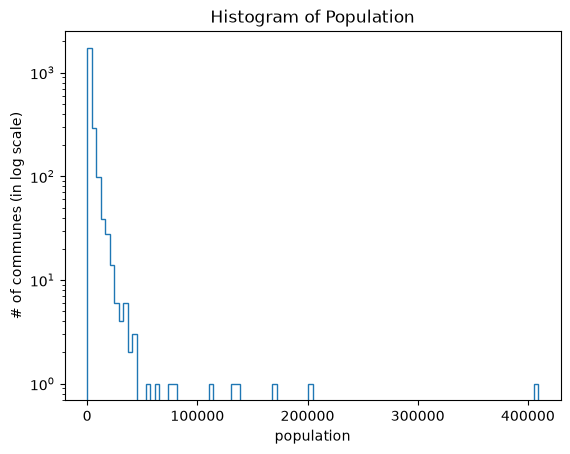

The log y-axis now makes the tail visible.Bins with 1 or 2 communes are now
visible next to the 1'750 in the first bin.


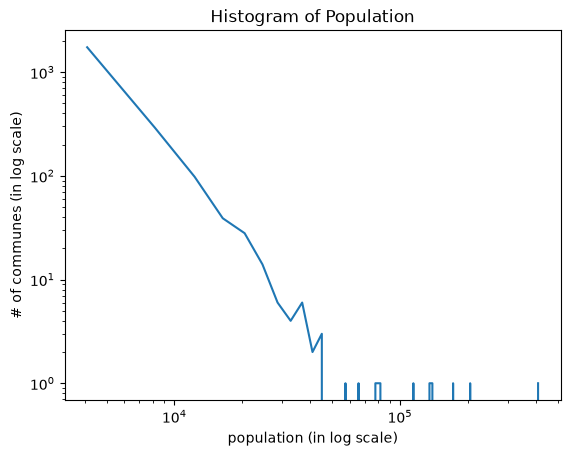

The points fall roughly on a straight descending line.A straight line on a log-
log plot means a power law:the number of communes of size x is proportional to
x^(−α).Frequency decreases as a power of population.


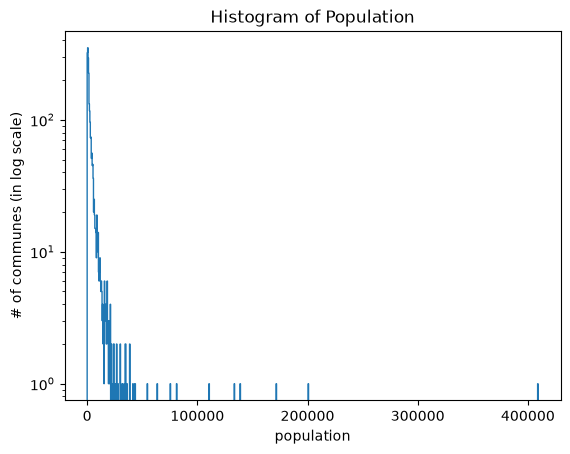

With narrow bins, most bins in the tail contain 0 or 1 commune.On a log axis, 0
can’t be drawn (log(0) is undefined), so those bins disappear,and the tail turns
into a flat, noisy row of points at count = 1.


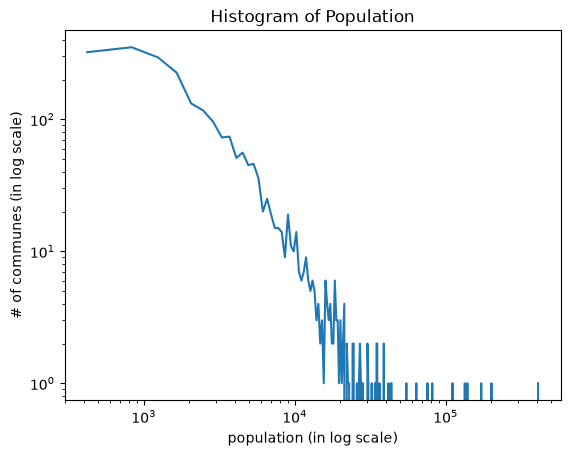

That flat row is an artifact. There aren’t “equally many” large communes at
every size;there’s just a minimum non-zero count per bin.With fewer, wider bins
(pair 1) the tail is averaged and the trend stays readable.


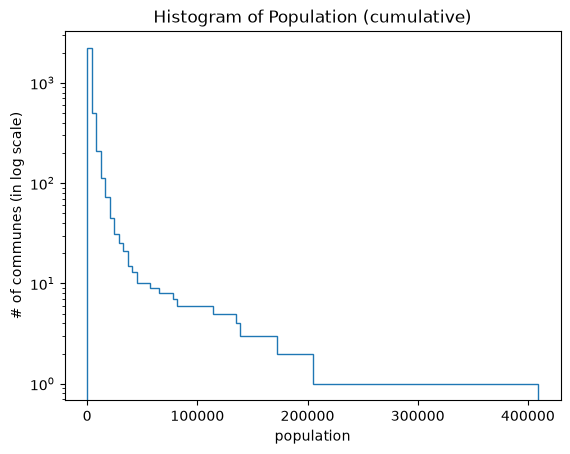

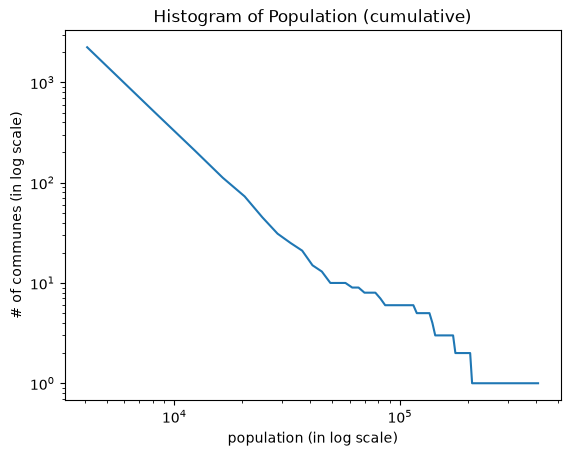

This is the cleanest representation. Each point summarizes all communes above
that size,so there are no empty bins and almost no noise, and the bin size
barely matters.If the data follows a power law, this curve is also a straight
line, with slope −(α−1).It’s the most reliable plot for judging whether the
distribution is power-law-like.


In [1451]:
import textwrap

# The six plots are three pairs. In each pair, 
# the first plot is a histogram with a log y-axis only (semi-log histogram), 
# and the second redraws the same counts with both axes logarithmic (log log histogram).

array_100 = plt.hist(pop_per_commune.population_Dec,bins=100,log=True,histtype='step')
plt.title('Histogram of Population')
plt.ylabel('# of communes (in log scale)')
plt.xlabel('population')
plt.show()
text = (
    "The log y-axis now makes the tail visible."
    "Bins with 1 or 2 communes are now visible next to the 1'750 in the first bin."
    )
print(textwrap.fill(text, width=80))

plt.loglog(array_100[1][1:],array_100[0])
plt.title('Histogram of Population')
plt.ylabel('# of communes (in log scale)')
plt.xlabel('population (in log scale)')
plt.show()
text = (
    "The points fall roughly on a straight descending line." 
    "A straight line on a log-log plot means a power law:"
    "the number of communes of size x is proportional to x^(−α)."
    "Frequency decreases as a power of population."
    )
print(textwrap.fill(text, width=80))

# The same plots with bins 10× narrower. This pair shows how binning creates artifacts.
array_1000 = plt.hist(pop_per_commune.population_Dec,bins=1000,log=True,histtype='step')
plt.title('Histogram of Population')
plt.ylabel('# of communes (in log scale)')
plt.xlabel('population')
plt.show()
text = (
    "With narrow bins, most bins in the tail contain 0 or 1 commune." 
    "On a log axis, 0 can’t be drawn (log(0) is undefined), so those bins disappear," 
    "and the tail turns into a flat, noisy row of points at count = 1."
    )
print(textwrap.fill(text, width=80))

plt.loglog(array_1000[1][1:],array_1000[0])
plt.title('Histogram of Population')
plt.ylabel('# of communes (in log scale)')
plt.xlabel('population (in log scale)')
plt.show()
text = ("That flat row is an artifact. There aren’t “equally many” large communes at every size;" 
      "there’s just a minimum non-zero count per bin." 
      "With fewer, wider bins (pair 1) the tail is averaged and the trend stays readable."
    )
print(textwrap.fill(text, width=80))

# Complementary cumulative distribution (CCDF)
array_cumulative=plt.hist(pop_per_commune.population_Dec,bins=100,log=True,cumulative=-1,histtype='step')
plt.title('Histogram of Population (cumulative)')
plt.ylabel('# of communes (in log scale)')
plt.xlabel('population')
plt.show()

plt.loglog(array_cumulative[1][1:],array_cumulative[0])
plt.title('Histogram of Population (cumulative)')
plt.ylabel('# of communes (in log scale)')
plt.xlabel('population (in log scale)')
plt.show()
text = ("This is the cleanest representation. Each point summarizes all communes above that size," 
      "so there are no empty bins and almost no noise, and the bin size barely matters." 
      "If the data follows a power law, this curve is also a straight line, with slope −(α−1)." 
      "It’s the most reliable plot for judging whether the distribution is power-law-like."
    )
print(textwrap.fill(text, width=80))

### Write your interpretations here
What to take away:

Commune populations are heavy-tailed, roughly a power law: many small communes, few large ones, and the frequency decreases as a power of population.

Histograms of such data depend on the binning: narrow bins produce noise and a false “flat” tail where counts are 0 or 1.

The cumulative log-log plot avoids those binning problems and is the best way to check for a power law.